In [98]:
import numpy as np
import matplotlib.pyplot as plt
from double_stopping_env import *
from tabulate import tabulate

In [99]:
class DoubleOptimalStopping:
    def __init__(self, env):
        self.env = env
        self.N = self.env.horizon
        self.vN_1, self.vN_2 = self.dp()

    def dp(self):
        v = np.zeros((self.N + 1, 3))

        v[0, 1] = -np.inf
        v[1, 2] = 0
        for n in range(1, self.N):
            v[n, 1] = self.env.exp_max(self.N - n + 1, v[n - 1, 1] - self.env.cost)
        for n in range(2, self.N + 1):
            v[n, 2] = (
                self.env.exp_max(self.N - n + 1, v[n - 1, 2] - v[n - 1, 1])
                + v[n - 1, 1]
                - self.env.cost
            )

        return v[:, 1], v[:, 2]

    def plot(self):
        N_values = np.arange(self.env.horizon + 1)

        plt.figure(figsize=(8, 5))
        plt.plot(N_values[:-1], self.vN_1[:-1], label="$v_{N,1}$", marker="o")
        plt.plot(N_values[2:], self.vN_2[2:], label="$v_{N,2}$", marker="s")
        plt.xlabel("N")
        plt.ylabel("Value")
        plt.title("Optimal Stopping Values vs. N")
        plt.figtext(
            0.5,
            -0.1,
            f"Max offer={self.env.max_offer}, cost={self.env.cost}, horizon={self.env.horizon}",
        )
        plt.legend()
        plt.grid()
        plt.show()

    def print(self):
        N_values = np.arange(self.env.horizon + 1)[::-1]
        table_data = [
            [N, v1, v2] for N, v1, v2 in zip(N_values, self.vN_1[::-1], self.vN_2[::-1])
        ]
        print(tabulate(table_data, headers=["N", "vN_1", "vN_2"], tablefmt="grid"))

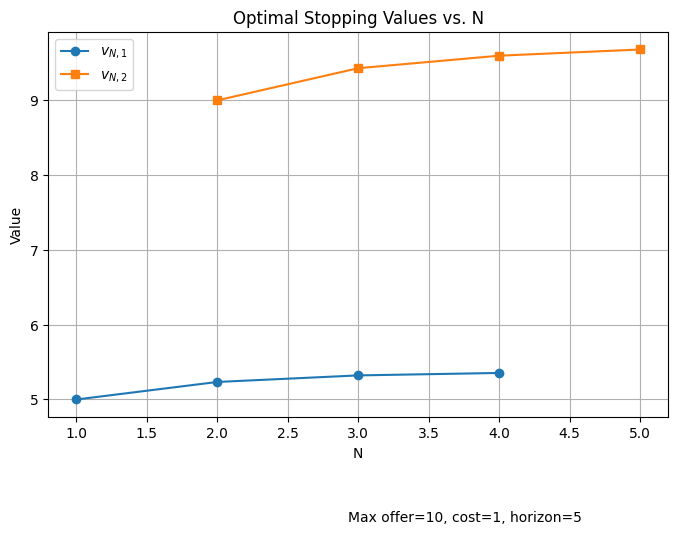

+-----+------------+---------+
|   N |       vN_1 |    vN_2 |
+=====+============+=========+
|   5 |    0       | 9.67997 |
+-----+------------+---------+
|   4 |    5.35497 | 9.59699 |
+-----+------------+---------+
|   3 |    5.3222  | 9.42987 |
+-----+------------+---------+
|   2 |    5.23454 | 9       |
+-----+------------+---------+
|   1 |    5       | 0       |
+-----+------------+---------+
|   0 | -inf       | 0       |
+-----+------------+---------+


In [100]:
env = HouseSellingEnv(max_offer=10, cost=1, horizon=5)
agent = DoubleOptimalStopping(env)
agent.plot()
agent.print()

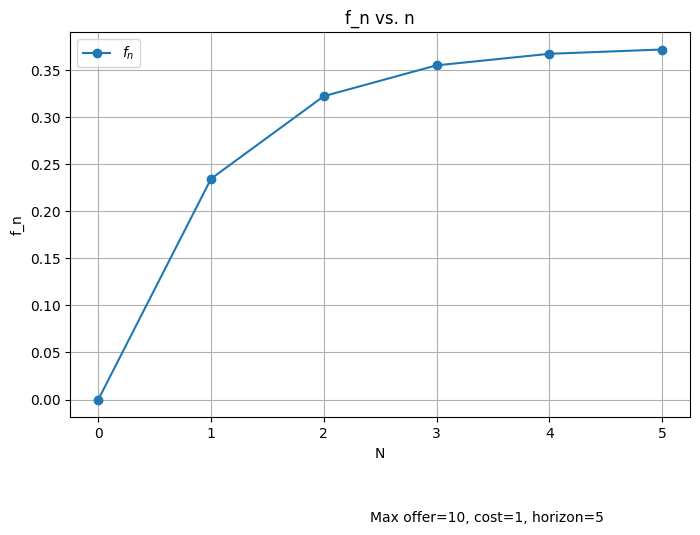

In [101]:
f_vals = env.f_vals()
N_values = np.arange(env.horizon + 1)

plt.figure(figsize=(8, 5))
plt.plot(N_values, f_vals, label="$f_n$", marker="o")
plt.xlabel("N")
plt.ylabel("f_n")
plt.title("f_n vs. n")
plt.figtext(
    0.5,
    -0.1,
    f"Max offer={env.max_offer}, cost={env.cost}, horizon={env.horizon}",
)
plt.legend()
plt.grid()
plt.show()

In [102]:
def train(env, num_episodes=1000):
    agent = DoubleOptimalStopping(env)
    returns = []
    for episode in range(num_episodes):
        sequence = env.generate_sequence()
        actions_remaining = 1
        ep_return = 0
        for t in range(env.horizon):
            # if episode % 1000 == 0:
            #     print(t, sequence[t], actions_remaining, ep_return)
            if actions_remaining == 0:
                break
            elif actions_remaining == 1:
                if sequence[t] >= agent.vN_1[env.horizon - t -1] - env.cost:
                    ep_return += sequence[t]
                    actions_remaining -= 1
            else:
                if (
                    sequence[t] + agent.vN_1[env.horizon - t-1]
                    >= agent.vN_2[env.horizon - t-1]
                ):
                    ep_return += sequence[t]
                    actions_remaining -= 1
            if actions_remaining > 0:
                ep_return -= env.cost
        returns.append(ep_return)
    # print(returns)
    return np.mean(returns)

In [103]:
num_episodes = 10000
returns = train(env, num_episodes)
print(f"Average return over {num_episodes} episodes: {returns}")
print(f"Predicted Value: {agent.vN_1[env.horizon-1]}")

Average return over 10000 episodes: 6.0812
Predicted Value: 5.354973113108549


## Markovian Envt (Single Optimal Stopping House Selling TPM)

In [104]:
class MarkovianDoubleOptimalStopping:
    def __init__(self, env):
        self.env = env
        self.N = env.horizon
        self.S = env.states
        self.cost = env.cost
        self.vN_1, self.vN_2 = self.dp()

    def dp(self):
        num_states = len(self.S)
        v = np.zeros((self.N + 1, 3, num_states))

        # Initialization
        v[0, 1, :] = -np.inf  # Can't stop once
        v[1, 2, :] = 0        # Can't stop twice at n=1

        # First stopping rule value function: v[n,1,s]
        for n in range(1, self.N):
            for s in self.S:
                x = v[n - 1, 1, s] - self.cost
                v[n, 1, s] = self.env.exp_max(self.N - n + 1, x, s)

        # Second stopping rule value function: v[n,2,s]
        for n in range(2, self.N + 1):
            for s in self.S:
                x = v[n - 1, 2, s] - v[n - 1, 1, s]
                expected = self.env.exp_max(self.N - n + 1, x, s)
                v[n, 2, s] = expected + v[n - 1, 1, s] - self.cost

        return v[:, 1, :], v[:, 2, :]

    def plot(self, state_idx=5):
        """Plot vN_1 and vN_2 over time for a fixed state"""
        if state_idx < 0 or state_idx >= len(self.env.states):
            raise IndexError(f"Invalid state index: {state_idx}. Must be in [0, {len(self.env.states) - 1}].")

        N_values = np.arange(self.env.horizon + 1)

        plt.figure(figsize=(8, 5))
        plt.plot(N_values[:-1], self.vN_1[:-1, state_idx], label="$v_{N,1}$", marker="o")
        plt.plot(N_values[2:], self.vN_2[2:, state_idx], label="$v_{N,2}$", marker="s")
        plt.xlabel("N (Time Horizon Remaining)")
        plt.ylabel("Value")
        plt.title(f"Optimal Stopping Values for State {state_idx}")
        plt.figtext(
            0.5,
            -0.1,
            f"Max offer={self.env.max_offer}, cost={self.env.cost}, horizon={self.env.horizon}",
            ha="center"
        )
        plt.legend()
        plt.grid()
        plt.show()

    def print(self, state_idx):
        if state_idx < 0 or state_idx >= len(self.env.states):
            raise IndexError(f"Invalid state index: {state_idx}. Must be in [0, {len(self.env.states) - 1}].")

        N_values = np.arange(self.env.horizon + 1)[::-1]
        table_data = [
            [N, v1, v2]
            for N, v1, v2 in zip(N_values, self.vN_1[::-1, state_idx], self.vN_2[::-1, state_idx])
        ]
        print(tabulate(table_data, headers=["N", "vN_1", "vN_2"], tablefmt="grid"))


In [105]:
# class MarkovianDoubleOptimalStopping:
#     def __init__(self, env):
#         self.env = env
#         self.T = env.horizon  # now T is the total time steps
#         self.S = env.states
#         self.cost = env.cost
#         self.v1, self.v2 = self.dp()

#     def dp(self):
#         num_states = len(self.S)
#         v = np.zeros((self.T + 1, 3, num_states))  # v[t, k, s]: value at time t, stop count k, state s

#         # Boundary conditions
#         v[self.T, 1, :] = -np.inf  # Can't do first stop at final time
#         v[self.T - 1, 2, :] = 0    # Can't do second stop at T-1

#         # Compute v_t,1 for t = T-1 to 0
#         for t in reversed(range(self.T)):
#             for s in self.S:
#                 y = v[t + 1, 1, s] - self.cost
#                 v[t, 1, s] = self.env.exp_max(t, y, s)

#         # Compute v_t,2 for t = T-1 to 0
#         for t in reversed(range(self.T-1)):
#             for s in self.S:
#                 y = v[t + 1, 2, s] - v[t, 1, s]
#                 expected = self.env.exp_max(t, y, s)
#                 v[t, 2, s] = expected + v[t, 1, s] - self.cost

#         return v[:, 1, :], v[:, 2, :]

#     def plot(self, state_idx=5):
#         if state_idx < 0 or state_idx >= len(self.env.states):
#             raise IndexError(f"Invalid state index: {state_idx}. Must be in [0, {len(self.env.states) - 1}].")

#         t_values = np.arange(self.env.horizon + 1)

#         plt.figure(figsize=(8, 5))
#         plt.plot(t_values, self.v1[:, state_idx], label="$v_{t,1}$", marker="o")
#         plt.plot(t_values, self.v2[:, state_idx], label="$v_{t,2}$", marker="s")
#         plt.xlabel("t (Current Time Step)")
#         plt.ylabel("Value")
#         plt.title(f"Optimal Stopping Values for State {state_idx}")
#         plt.figtext(
#             0.5,
#             -0.1,
#             f"Max offer={self.env.max_offer}, cost={self.env.cost}, horizon={self.env.horizon}",
#             ha="center"
#         )
#         plt.legend()
#         plt.grid()
#         plt.show()

#     def print(self, state_idx=5):
#         if state_idx < 0 or state_idx >= len(self.env.states):
#             raise IndexError(f"Invalid state index: {state_idx}. Must be in [0, {len(self.env.states) - 1}].")

#         t_values = np.arange(self.env.horizon + 1)
#         table_data = [
#             [t, v1, v2]
#             for t, v1, v2 in zip(t_values, self.v1[:, state_idx], self.v2[:, state_idx])
#         ]
#         print(tabulate(table_data, headers=["t", "v_t,1", "v_t,2"], tablefmt="grid"))


In [106]:

class MarkovianHouseSellingEnv:
    def __init__(self, horizon=10, cost=10, max_offer=100, alpha=1.0):
        self.horizon = horizon
        self.cost = cost
        self.max_offer = max_offer
        self.states = [i for i in range(max_offer + 1)]
        self.actions = [0, 1]  # 0: Accept, 1: Reject
        self.alpha = alpha
        self._init_probabilities()
        self._init_TPM()

    def reset(self):
        return np.random.choice(self.states, p=self.P)

    def _init_probabilities(self):
        self.P = np.zeros(self.max_offer + 1)
        mu = self.max_offer / 2
        sigma = np.sqrt(self.max_offer / 4)
        for i in range(self.max_offer + 1):
            self.P[i] = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
                -((i - mu) ** 2) / (2 * sigma**2)
            )
        self.P /= np.sum(self.P)

    def _init_TPM(self):
        """Transition matrix TPM[s][s'] = P(s' | s)"""
        self.TPM = np.zeros((self.max_offer + 1, self.max_offer + 1))
        self.P_cumsum = np.cumsum(self.P)

        for s in range(self.max_offer + 1):
            for s_prime in range(self.max_offer + 1):
                if s_prime < s:
                    self.TPM[s, s_prime] = 0
                elif s_prime == s:
                    self.TPM[s, s_prime] = self.P_cumsum[s]
                else:
                    self.TPM[s, s_prime] = self.P[s_prime]

            self.TPM[s] /= np.sum(self.TPM[s])  # Normalize each row

    def get_next_state(self, s):
        return np.random.choice(self.states, p=self.TPM[s])

    def generate_sequence(self):
        sequence = [self.reset()]
        for _ in range(1, self.horizon):
            next_state = self.get_next_state(sequence[-1])
            sequence.append(next_state)
        return sequence

    def exp_max(self, n, x, s):
        """
        Conditional expected maximum:
        E_s[max(x, S_{t+1}) | S_t = s] = sum_{s'} max(x, s') * P(s' | s)
        """
        vals = np.array([max(x, s_prime) for s_prime in self.states])
        return np.dot(vals, self.TPM[s])

    # Optional utilities if needed
    def cdf(self):
        return np.cumsum(self.P)

    def exp_indictor_less_than(self, x):
        vals = np.array([i if i <= x else 0 for i in self.states])
        return np.dot(vals, self.P)


In [107]:
env2 = MarkovianHouseSellingEnv(max_offer=10, cost=1, horizon=10)
agent2 = MarkovianDoubleOptimalStopping(env2)

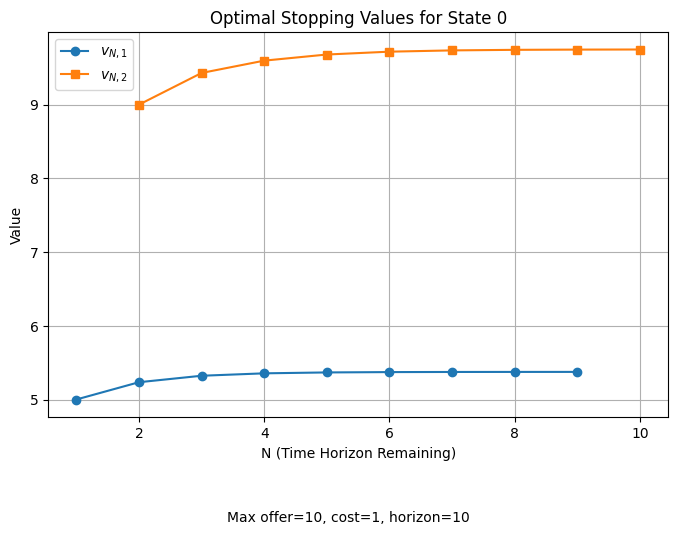

+-----+------------+---------+
|   N |       vN_1 |    vN_2 |
+=====+============+=========+
|  10 |    0       | 9.74812 |
+-----+------------+---------+
|   9 |    5.37439 | 9.74676 |
+-----+------------+---------+
|   8 |    5.37415 | 9.74354 |
+-----+------------+---------+
|   7 |    5.37351 | 9.73599 |
+-----+------------+---------+
|   6 |    5.3718  | 9.71866 |
+-----+------------+---------+
|   5 |    5.36722 | 9.67997 |
+-----+------------+---------+
|   4 |    5.35497 | 9.59699 |
+-----+------------+---------+
|   3 |    5.3222  | 9.42987 |
+-----+------------+---------+
|   2 |    5.23454 | 9       |
+-----+------------+---------+
|   1 |    5       | 0       |
+-----+------------+---------+
|   0 | -inf       | 0       |
+-----+------------+---------+


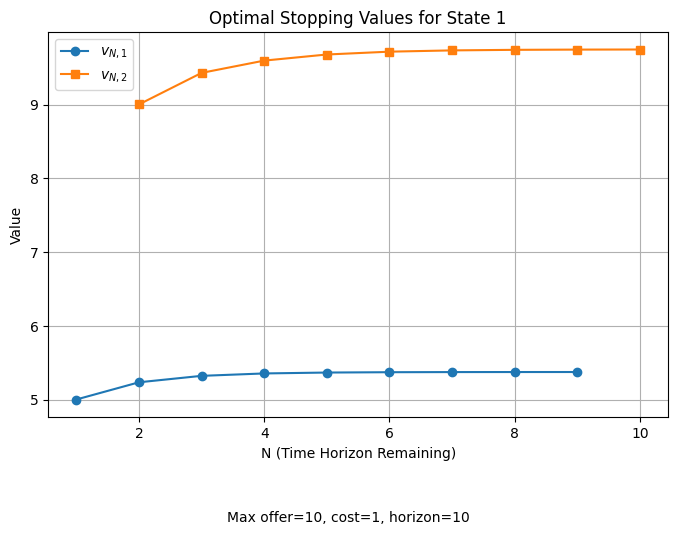

+-----+------------+---------+
|   N |       vN_1 |    vN_2 |
+=====+============+=========+
|  10 |    0       | 9.74812 |
+-----+------------+---------+
|   9 |    5.37439 | 9.74677 |
+-----+------------+---------+
|   8 |    5.37415 | 9.74356 |
+-----+------------+---------+
|   7 |    5.37352 | 9.73604 |
+-----+------------+---------+
|   6 |    5.37181 | 9.71878 |
+-----+------------+---------+
|   5 |    5.36726 | 9.68024 |
+-----+------------+---------+
|   4 |    5.35506 | 9.59754 |
+-----+------------+---------+
|   3 |    5.32244 | 9.43097 |
+-----+------------+---------+
|   2 |    5.23517 | 9.0034  |
+-----+------------+---------+
|   1 |    5.0017  | 0       |
+-----+------------+---------+
|   0 | -inf       | 0       |
+-----+------------+---------+


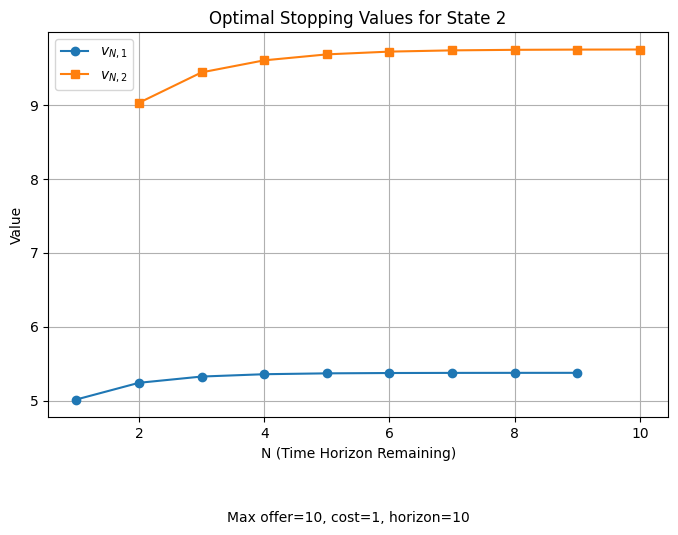

+-----+------------+---------+
|   N |       vN_1 |    vN_2 |
+=====+============+=========+
|  10 |    0       | 9.74815 |
+-----+------------+---------+
|   9 |    5.3744  | 9.74684 |
+-----+------------+---------+
|   8 |    5.37417 | 9.74372 |
+-----+------------+---------+
|   7 |    5.37355 | 9.73641 |
+-----+------------+---------+
|   6 |    5.3719  | 9.71962 |
+-----+------------+---------+
|   5 |    5.36749 | 9.6821  |
+-----+------------+---------+
|   4 |    5.35569 | 9.60149 |
+-----+------------+---------+
|   3 |    5.32412 | 9.43871 |
+-----+------------+---------+
|   2 |    5.23965 | 9.02738 |
+-----+------------+---------+
|   1 |    5.01369 | 0       |
+-----+------------+---------+
|   0 | -inf       | 0       |
+-----+------------+---------+


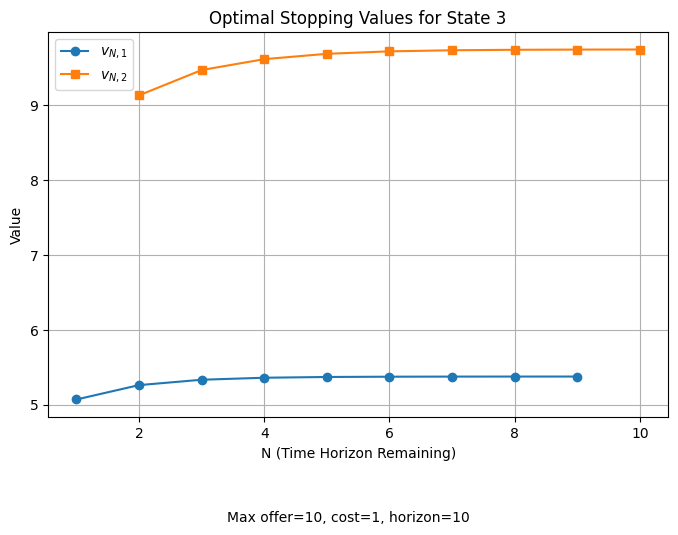

+-----+------------+---------+
|   N |       vN_1 |    vN_2 |
+=====+============+=========+
|  10 |    0       | 9.74827 |
+-----+------------+---------+
|   9 |    5.37442 | 9.74714 |
+-----+------------+---------+
|   8 |    5.37422 | 9.74443 |
+-----+------------+---------+
|   7 |    5.3737  | 9.73807 |
+-----+------------+---------+
|   6 |    5.37229 | 9.72341 |
+-----+------------+---------+
|   5 |    5.36854 | 9.69046 |
+-----+------------+---------+
|   4 |    5.35849 | 9.61915 |
+-----+------------+---------+
|   3 |    5.33162 | 9.47339 |
+-----+------------+---------+
|   2 |    5.25973 | 9.13481 |
+-----+------------+---------+
|   1 |    5.0674  | 0       |
+-----+------------+---------+
|   0 | -inf       | 0       |
+-----+------------+---------+


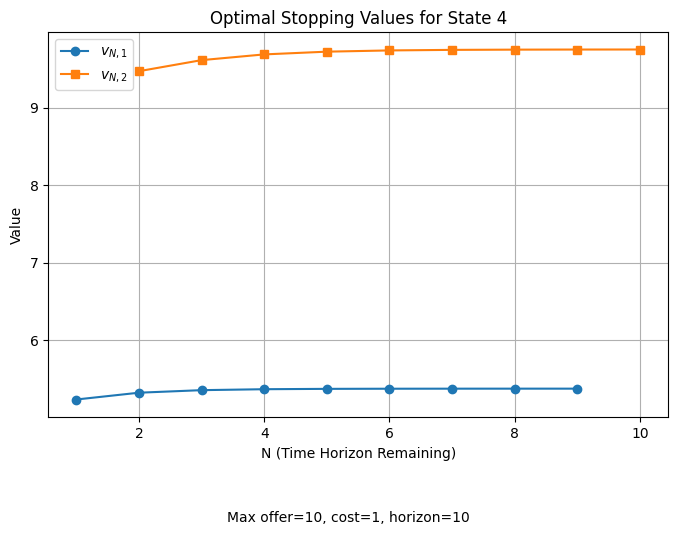

+-----+------------+---------+
|   N |       vN_1 |    vN_2 |
+=====+============+=========+
|  10 |    0       | 9.74869 |
+-----+------------+---------+
|   9 |    5.37448 | 9.74816 |
+-----+------------+---------+
|   8 |    5.37439 | 9.74687 |
+-----+------------+---------+
|   7 |    5.37415 | 9.74383 |
+-----+------------+---------+
|   6 |    5.37351 | 9.73676 |
+-----+------------+---------+
|   5 |    5.3718  | 9.72071 |
+-----+------------+---------+
|   4 |    5.36722 | 9.68545 |
+-----+------------+---------+
|   3 |    5.35497 | 9.61164 |
+-----+------------+---------+
|   2 |    5.3222  | 9.46907 |
+-----+------------+---------+
|   1 |    5.23454 | 0       |
+-----+------------+---------+
|   0 | -inf       | 0       |
+-----+------------+---------+


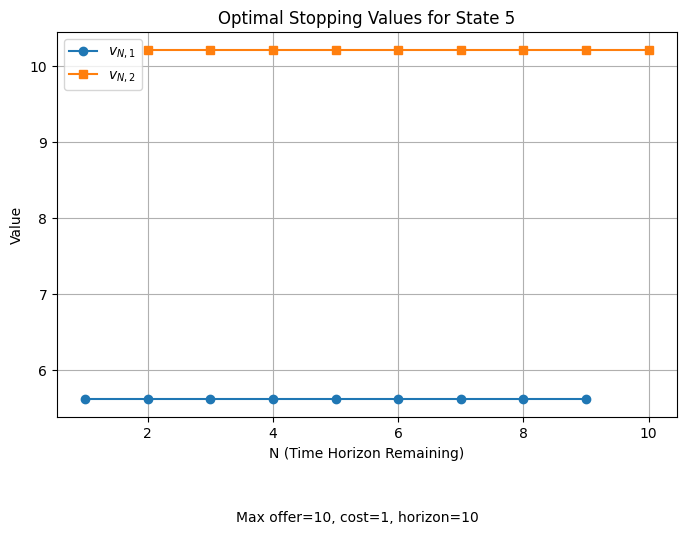

+-----+------------+---------+
|   N |       vN_1 |    vN_2 |
+=====+============+=========+
|  10 |    0       | 10.2167 |
+-----+------------+---------+
|   9 |    5.60833 | 10.2167 |
+-----+------------+---------+
|   8 |    5.60833 | 10.2167 |
+-----+------------+---------+
|   7 |    5.60833 | 10.2167 |
+-----+------------+---------+
|   6 |    5.60833 | 10.2167 |
+-----+------------+---------+
|   5 |    5.60833 | 10.2167 |
+-----+------------+---------+
|   4 |    5.60833 | 10.2167 |
+-----+------------+---------+
|   3 |    5.60833 | 10.2167 |
+-----+------------+---------+
|   2 |    5.60833 | 10.2167 |
+-----+------------+---------+
|   1 |    5.60833 |  0      |
+-----+------------+---------+
|   0 | -inf       |  0      |
+-----+------------+---------+


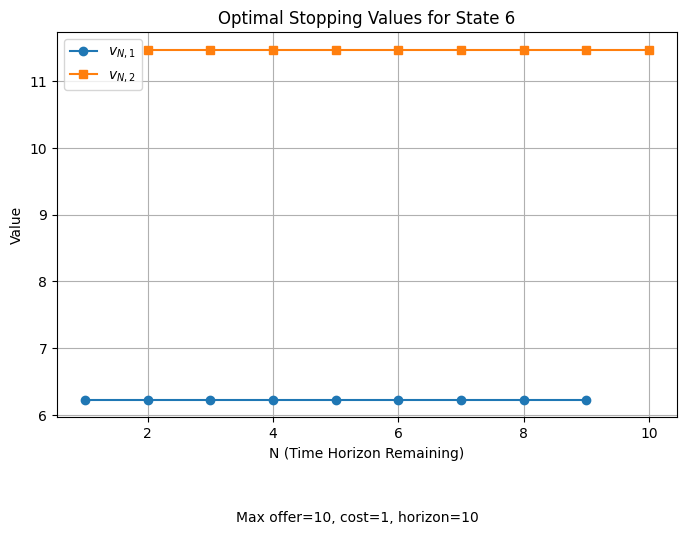

+-----+------------+---------+
|   N |       vN_1 |    vN_2 |
+=====+============+=========+
|  10 |    0       | 11.4691 |
+-----+------------+---------+
|   9 |    6.23454 | 11.4691 |
+-----+------------+---------+
|   8 |    6.23454 | 11.4691 |
+-----+------------+---------+
|   7 |    6.23454 | 11.4691 |
+-----+------------+---------+
|   6 |    6.23454 | 11.4691 |
+-----+------------+---------+
|   5 |    6.23454 | 11.4691 |
+-----+------------+---------+
|   4 |    6.23454 | 11.4691 |
+-----+------------+---------+
|   3 |    6.23454 | 11.4691 |
+-----+------------+---------+
|   2 |    6.23454 | 11.4691 |
+-----+------------+---------+
|   1 |    6.23454 |  0      |
+-----+------------+---------+
|   0 | -inf       |  0      |
+-----+------------+---------+


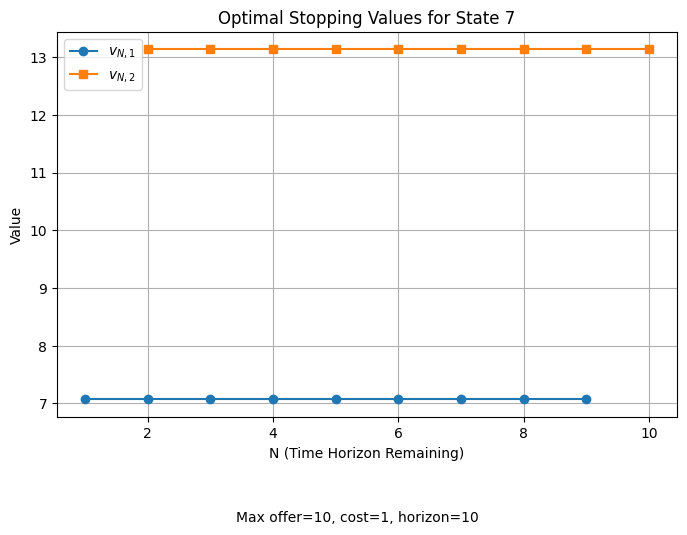

+-----+-----------+---------+
|   N |      vN_1 |    vN_2 |
+=====+===========+=========+
|  10 |    0      | 13.1348 |
+-----+-----------+---------+
|   9 |    7.0674 | 13.1348 |
+-----+-----------+---------+
|   8 |    7.0674 | 13.1348 |
+-----+-----------+---------+
|   7 |    7.0674 | 13.1348 |
+-----+-----------+---------+
|   6 |    7.0674 | 13.1348 |
+-----+-----------+---------+
|   5 |    7.0674 | 13.1348 |
+-----+-----------+---------+
|   4 |    7.0674 | 13.1348 |
+-----+-----------+---------+
|   3 |    7.0674 | 13.1348 |
+-----+-----------+---------+
|   2 |    7.0674 | 13.1348 |
+-----+-----------+---------+
|   1 |    7.0674 |  0      |
+-----+-----------+---------+
|   0 | -inf      |  0      |
+-----+-----------+---------+


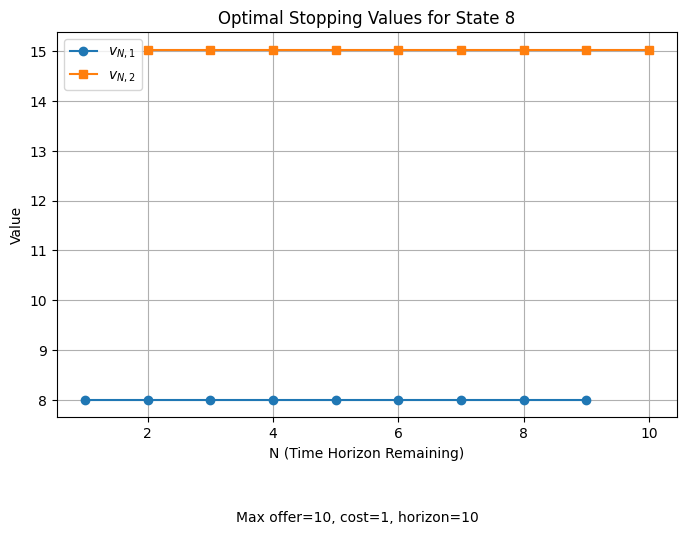

+-----+------------+---------+
|   N |       vN_1 |    vN_2 |
+=====+============+=========+
|  10 |    0       | 15.0274 |
+-----+------------+---------+
|   9 |    8.01369 | 15.0274 |
+-----+------------+---------+
|   8 |    8.01369 | 15.0274 |
+-----+------------+---------+
|   7 |    8.01369 | 15.0274 |
+-----+------------+---------+
|   6 |    8.01369 | 15.0274 |
+-----+------------+---------+
|   5 |    8.01369 | 15.0274 |
+-----+------------+---------+
|   4 |    8.01369 | 15.0274 |
+-----+------------+---------+
|   3 |    8.01369 | 15.0274 |
+-----+------------+---------+
|   2 |    8.01369 | 15.0274 |
+-----+------------+---------+
|   1 |    8.01369 |  0      |
+-----+------------+---------+
|   0 | -inf       |  0      |
+-----+------------+---------+


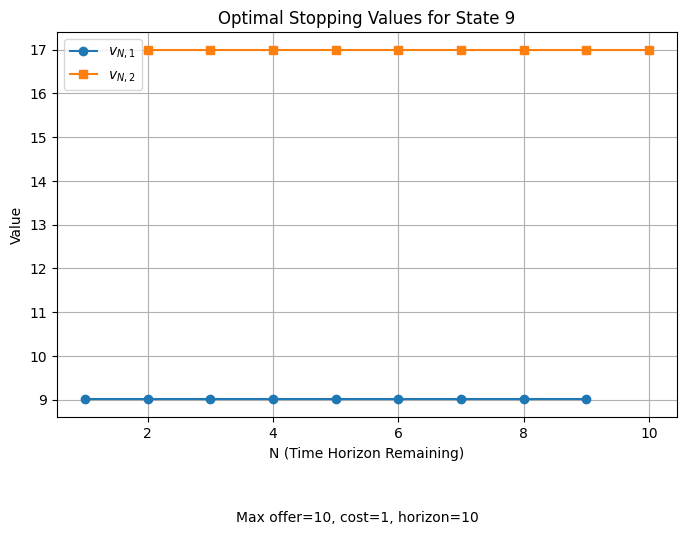

+-----+-----------+---------+
|   N |      vN_1 |    vN_2 |
+=====+===========+=========+
|  10 |    0      | 17.0034 |
+-----+-----------+---------+
|   9 |    9.0017 | 17.0034 |
+-----+-----------+---------+
|   8 |    9.0017 | 17.0034 |
+-----+-----------+---------+
|   7 |    9.0017 | 17.0034 |
+-----+-----------+---------+
|   6 |    9.0017 | 17.0034 |
+-----+-----------+---------+
|   5 |    9.0017 | 17.0034 |
+-----+-----------+---------+
|   4 |    9.0017 | 17.0034 |
+-----+-----------+---------+
|   3 |    9.0017 | 17.0034 |
+-----+-----------+---------+
|   2 |    9.0017 | 17.0034 |
+-----+-----------+---------+
|   1 |    9.0017 |  0      |
+-----+-----------+---------+
|   0 | -inf      |  0      |
+-----+-----------+---------+


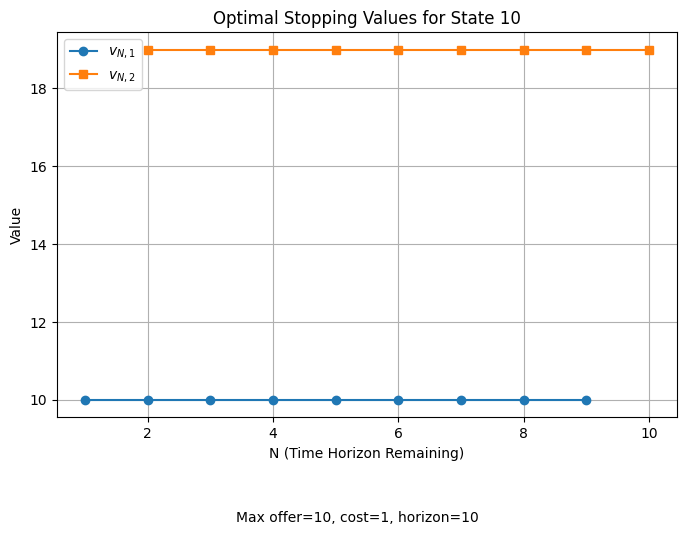

+-----+--------+--------+
|   N |   vN_1 |   vN_2 |
+=====+========+========+
|  10 |      0 |     19 |
+-----+--------+--------+
|   9 |     10 |     19 |
+-----+--------+--------+
|   8 |     10 |     19 |
+-----+--------+--------+
|   7 |     10 |     19 |
+-----+--------+--------+
|   6 |     10 |     19 |
+-----+--------+--------+
|   5 |     10 |     19 |
+-----+--------+--------+
|   4 |     10 |     19 |
+-----+--------+--------+
|   3 |     10 |     19 |
+-----+--------+--------+
|   2 |     10 |     19 |
+-----+--------+--------+
|   1 |     10 |      0 |
+-----+--------+--------+
|   0 |   -inf |      0 |
+-----+--------+--------+


In [108]:
for i in (env2.states):
    agent2.plot(state_idx=i)
    agent2.print(state_idx=i)